<a href="https://colab.research.google.com/github/pramodmane1988/sugarcane-MSVE-app/blob/main/sugarMSVE1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

DATASET_PATH = Path(
    "/content/drive/MyDrive/Sugarcane_Dataset"
)

print("Dataset exists:", DATASET_PATH.exists())

if DATASET_PATH.exists():
    for folder in sorted(DATASET_PATH.iterdir()):
        if folder.is_dir():
            image_count = sum(
                1 for f in folder.iterdir()
                if f.is_file()
            )
            print(folder.name, ":", image_count, "files")

Dataset exists: True
Healthy : 453 files
Mosaic : 407 files
RedRot : 451 files
Rust : 465 files
Yellow : 438 files


In [ ]:
import random
import numpy as np
import torch

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 16

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Image transformations

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        224, scale=(0.80, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Read class names and image paths
base_dataset = datasets.ImageFolder(str(DATASET_PATH))
class_names = base_dataset.classes
targets = np.array(base_dataset.targets)
indices = np.arange(len(targets))

print("Classes:", class_names)
print("Total images:", len(base_dataset))

# Split: 70% train, 15% validation, 15% test
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=targets
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=targets[temp_idx]
)

# Separate dataset instances let training and evaluation use
# different transformations while sharing the same file ordering.
train_dataset = datasets.ImageFolder(
    str(DATASET_PATH), transform=train_transform
)
eval_dataset = datasets.ImageFolder(
    str(DATASET_PATH), transform=eval_transform
)

train_loader = DataLoader(
    Subset(train_dataset, train_idx),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    Subset(eval_dataset, val_idx),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    Subset(eval_dataset, test_idx),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Training images:", len(train_idx))
print("Validation images:", len(val_idx))
print("Test images:", len(test_idx))
print("Class mapping:", base_dataset.class_to_idx)

Classes: ['Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']
Total images: 2214
Training images: 1549
Validation images: 332
Test images: 333
Class mapping: {'Healthy': 0, 'Mosaic': 1, 'RedRot': 2, 'Rust': 3, 'Yellow': 4}


In [ ]:
import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet50_Weights


class SugarcaneMSVE(nn.Module):

    def __init__(
        self,
        input_channels=3,
        feature_dims=512,
        num_classes=5,
        pretrained=True
    ):
        super().__init__()

        # ----------------------------------------------------
        # SCALE 1: LARGE RECEPTIVE FIELD
        # Output: [B, 128, 14, 14]
        # ----------------------------------------------------
        self.scale1 = nn.Sequential(
            nn.Conv2d(
                input_channels, 64,
                kernel_size=7, stride=2, padding=3
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(
                kernel_size=3, stride=2, padding=1
            ),

            nn.Conv2d(
                64, 128,
                kernel_size=5, padding=2
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((14, 14))
        )

        # ----------------------------------------------------
        # SCALE 2: MEDIUM RECEPTIVE FIELD
        # Output: [B, 256, 14, 14]
        # ----------------------------------------------------
        self.scale2 = nn.Sequential(
            nn.Conv2d(
                input_channels, 128,
                kernel_size=3, stride=2, padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                128, 256,
                kernel_size=3, stride=2, padding=1
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((14, 14))
        )

        # ----------------------------------------------------
        # SCALE 3: FINE-GRAINED FEATURES
        # Output: [B, 512, 14, 14]
        # ----------------------------------------------------
        self.scale3 = nn.Sequential(
            nn.Conv2d(
                input_channels, 256,
                kernel_size=3, padding=1
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                256, 512,
                kernel_size=3, padding=1
            ),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((14, 14))
        )

        # ----------------------------------------------------
        # SCALE 4: PRETRAINED RESNET50
        # Uses ImageNet-pretrained low/mid-level features.
        # For 224x224 input, layer2 outputs 512 x 14 x 14.
        # Project to 256 channels.
        # ----------------------------------------------------
        weights = (
            ResNet50_Weights.DEFAULT if pretrained else None
        )
        backbone = models.resnet50(weights=weights)

        self.pretrained_backbone = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
            backbone.layer1,
            backbone.layer2
        )


        self.pretrained_projection = nn.Sequential(
            nn.Conv2d(512, 256, kernel_size=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((14, 14))
        )


        # Total channels = 128 + 256 + 512 + 256 = 1152
        total_channels = 1152

        # ----------------------------------------------------
        # FOUR-SCALE SPATIAL ATTENTION
        # One attention map per feature scale.
        # ----------------------------------------------------
        self.attention = nn.Sequential(
            nn.Conv2d(
                total_channels, 256, kernel_size=1
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.Conv2d(256, 4, kernel_size=1)
        )

        # ----------------------------------------------------
        # MULTI-SCALE FEATURE FUSION
        # ----------------------------------------------------
        self.fusion = nn.Sequential(
            nn.Conv2d(
                total_channels, feature_dims,
                kernel_size=1
            ),
            nn.BatchNorm2d(feature_dims),
            nn.ReLU(inplace=True),
            nn.Dropout2d(p=0.2)
        )

        # ----------------------------------------------------
        # CLASSIFICATION HEAD
        # ----------------------------------------------------
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(feature_dims, num_classes)
        )

    def forward(self, x):

        # Extract features from all four scales
        s1 = self.scale1(x)
        s2 = self.scale2(x)
        s3 = self.scale3(x)

        pretrained_features = self.pretrained_backbone(x)
        s4 = self.pretrained_projection(pretrained_features)

        # Concatenate: [B, 1152, 14, 14]
        combined = torch.cat(
            [s1, s2, s3, s4], dim=1
        )

        # Spatial attention weights: [B, 4, 14, 14]
        attention_maps = torch.softmax(
            self.attention(combined), dim=1
        )

        # Apply one spatial attention map per scale
        weighted_s1 = s1 * attention_maps[:, 0:1]
        weighted_s2 = s2 * attention_maps[:, 1:2]
        weighted_s3 = s3 * attention_maps[:, 2:3]
        weighted_s4 = s4 * attention_maps[:, 3:4]

        # Concatenate weighted features
        weighted_features = torch.cat(
            [
                weighted_s1,
                weighted_s2,
                weighted_s3,
                weighted_s4
            ],
            dim=1
        )

        # Fuse all scales
        fused_features = self.fusion(weighted_features)

        # Predict class logits
        logits = self.classifier(fused_features)

        return logits

In [ ]:
# Set the number of classes to match your dataset

NUM_CLASSES = len(class_names)

model = SugarcaneMSVE(
    input_channels=3,
    feature_dims=512,
    num_classes=NUM_CLASSES,
    pretrained=True
).to(device)

# Check that the model output has the correct shape.
dummy_input = torch.randn(2, 3, 224, 224).to(device)

model.eval()
with torch.no_grad():
    output = model(dummy_input)

print("Classes:", class_names)
print("Device:", device)
print("Output shape:", output.shape)
print("Parameters:", sum(
    p.numel() for p in model.parameters()
))

assert output.shape == (2, NUM_CLASSES)
print("Updated MSVE model test passed!")


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 149MB/s]


Classes: ['Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']
Device: cpu
Output shape: torch.Size([2, 5])
Parameters: 4170569
Updated MSVE model test passed!


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SugarcaneMSVE(
    input_channels=3,
    feature_dims=512,
    num_classes=len(class_names)
).to(device)

print("Device:", device)
print("Number of classes:", len(class_names))
print("Classes:", class_names)
print("Model created successfully!")

Device: cpu
Number of classes: 5
Classes: ['Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']
Model created successfully!


In [ ]:
import copy
import pandas as pd
from pathlib import Path
from collections import Counter

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

EPOCHS = 60
PATIENCE = 10
LEARNING_RATE = 0.0003
BACKBONE_LR = 0.00001
WEIGHT_DECAY = 0.0001

OUTPUT_PATH = Path(
    "/content/drive/MyDrive/MSVE_Experiments1"
)
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

# Count labels in the training split
if "train_idx" in globals() and "targets" in globals():
    train_labels = targets[train_idx]
else:
    # Fallback for an existing train_loader
    train_labels = []
    for _, labels in train_loader:
        train_labels.extend(labels.tolist())

counts = Counter(map(int, train_labels))
num_classes = len(class_names)

class_counts = torch.tensor(
    [counts.get(i, 0) for i in range(num_classes)],
    dtype=torch.float32
)

if (class_counts == 0).any():
    raise ValueError(
        "At least one class has no training samples. "
        f"Class counts: {class_counts.tolist()}"
    )

class_weights = class_counts.sum() / (
    num_classes * class_counts
)
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": []
}

best_val_f1 = -1.0
best_state = None
bad_epochs = 0

def evaluate_model(model, loader):
    model.eval()

    y_true = []
    y_pred = []
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            with torch.autocast(
                device_type=device.type,
                enabled=use_amp
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            total_loss += loss.item() * labels.size(0)
            total_samples += labels.size(0)

            predictions = logits.argmax(dim=1)

            y_true.extend(labels.cpu().tolist())
            y_pred.extend(predictions.cpu().tolist())

    return {
        "loss": total_loss / max(total_samples, 1),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "y_true": y_true,
        "y_pred": y_pred
    }

for epoch in range(EPOCHS):

    model.train()
    running_loss = 0.0
    sample_count = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=use_amp
        ):
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * labels.size(0)
        sample_count += labels.size(0)

    train_loss = running_loss / max(sample_count, 1)
    val = evaluate_model(model, val_loader)

    scheduler.step(val["f1"])

    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val["loss"])
    history["val_accuracy"].append(val["accuracy"])
    history["val_precision"].append(val["precision"])
    history["val_recall"].append(val["recall"])
    history["val_f1"].append(val["f1"])

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val['loss']:.4f} | "
        f"Val Accuracy: {val['accuracy']:.4f} | "
        f"Val Macro-F1: {val['f1']:.4f}"
    )

    if val["f1"] > best_val_f1:
        best_val_f1 = val["f1"]
        best_state = copy.deepcopy(model.state_dict())

        torch.save(
            best_state,
            OUTPUT_PATH / "msve_best.pth"
        )
        bad_epochs = 0
    else:
        bad_epochs += 1

    if bad_epochs >= PATIENCE:
        print("Early stopping: validation macro-F1 did not improve.")
        break

# Save training history
history_df = pd.DataFrame(history)
history_df.to_csv(
    OUTPUT_PATH / "msve_training_history.csv",
    index=False
)

print("\nBest validation macro-F1:", round(best_val_f1, 4))
print("Checkpoint:", OUTPUT_PATH / "msve_best.pth")

Epoch 01/60 | Train Loss: 0.8445 | Val Loss: 0.4767 | Val Accuracy: 0.8343 | Val Macro-F1: 0.8330
Epoch 02/60 | Train Loss: 0.4459 | Val Loss: 0.2329 | Val Accuracy: 0.9367 | Val Macro-F1: 0.9368
Epoch 03/60 | Train Loss: 0.3000 | Val Loss: 0.2257 | Val Accuracy: 0.9307 | Val Macro-F1: 0.9304
Epoch 04/60 | Train Loss: 0.2613 | Val Loss: 0.1975 | Val Accuracy: 0.9307 | Val Macro-F1: 0.9315
Epoch 05/60 | Train Loss: 0.1927 | Val Loss: 0.2085 | Val Accuracy: 0.9337 | Val Macro-F1: 0.9332
Epoch 06/60 | Train Loss: 0.1524 | Val Loss: 0.1118 | Val Accuracy: 0.9608 | Val Macro-F1: 0.9603
Epoch 07/60 | Train Loss: 0.1292 | Val Loss: 0.1605 | Val Accuracy: 0.9548 | Val Macro-F1: 0.9543
Epoch 08/60 | Train Loss: 0.1043 | Val Loss: 0.1088 | Val Accuracy: 0.9759 | Val Macro-F1: 0.9759
Epoch 09/60 | Train Loss: 0.0943 | Val Loss: 0.0891 | Val Accuracy: 0.9699 | Val Macro-F1: 0.9697
Epoch 10/60 | Train Loss: 0.0908 | Val Loss: 0.1033 | Val Accuracy: 0.9729 | Val Macro-F1: 0.9729
Epoch 11/60 | Train 

In [1]:
import torchvision.models as models
import torch.nn as nn

def build_baseline(name, num_classes):
    if name == "ResNet50":
        model = models.resnet50(weights=None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif name == "DenseNet121":
        model = models.densenet121(weights=None)
        model.classifier = nn.Linear(
            model.classifier.in_features, num_classes
        )

    elif name == "EfficientNetB0":
        model = models.efficientnet_b0(weights=None)
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features, num_classes
        )

    elif name == "MobileNetV3":
        model = models.mobilenet_v3_large(weights=None)
        model.classifier[3] = nn.Linear(
            model.classifier[3].in_features, num_classes
        )

    else:
        raise ValueError(f"Unknown model: {name}")

    return model

In [2]:
import copy
import torch
import torch.nn as nn
import pandas as pd

def train_model(model_instance, model_name, epochs=20, patience=7, lr=0.0003):
    # Move model to device
    model_instance = model_instance.to(device)

    # Setup Loss Criterion with pre-computed class weights
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

    # Setup Optimizer and Scheduler
    optimizer = torch.optim.AdamW(model_instance.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

    use_amp = (device.type == 'cuda')
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    local_history = {
        "epoch": [],
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_precision": [],
        "val_recall": [],
        "val_f1": []
    }

    best_val_f1 = -1.0
    best_state = None
    bad_epochs = 0
    checkpoint_path = OUTPUT_PATH / f"{model_name.lower()}_best.pth"

    for epoch in range(epochs):
        model_instance.train()
        running_loss = 0.0
        sample_count = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits = model_instance(images)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model_instance.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * labels.size(0)
            sample_count += labels.size(0)

        train_loss = running_loss / max(sample_count, 1)

        # Use the global evaluate_model helper
        val = evaluate_model(model_instance, val_loader)
        scheduler.step(val["f1"])

        local_history["epoch"].append(epoch + 1)
        local_history["train_loss"].append(train_loss)
        local_history["val_loss"].append(val["loss"])
        local_history["val_accuracy"].append(val["accuracy"])
        local_history["val_precision"].append(val["precision"])
        local_history["val_recall"].append(val["recall"])
        local_history["val_f1"].append(val["f1"])

        print(f"Epoch {epoch + 1:02d}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val['loss']:.4f} | Val Accuracy: {val['accuracy']:.4f} | Val Macro-F1: {val['f1']:.4f}")

        if val["f1"] > best_val_f1:
            best_val_f1 = val["f1"]
            best_state = copy.deepcopy(model_instance.state_dict())
            torch.save(best_state, checkpoint_path)
            bad_epochs = 0
        else:
            bad_epochs += 1

        if bad_epochs >= patience:
            print(f"Early stopping for {model_name}.")
            break

    # Load best weights before returning
    model_instance.load_state_dict(best_state)
    history_df = pd.DataFrame(local_history)
    history_df.to_csv(OUTPUT_PATH / f"{model_name.lower()}_training_history.csv", index=False)

    return model_instance, history_df, checkpoint_path

In [6]:
# Define class_names to resolve the NameError
try:
    class_names = base_dataset.classes
except NameError:
    class_names = ['Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']

print("Class names defined:", class_names)

Class names defined: ['Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']


In [7]:
# Explicitly load and define class_names from the dataset
try:
    class_names = base_dataset.classes
except NameError:
    class_names = ['Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']

print("Loaded class names for training:", class_names)

baseline_names = [
    "ResNet50",
    "DenseNet121",
    "EfficientNetB0",
    "MobileNetV3"
]

baseline_models = {}
baseline_histories = {}

for name in baseline_names:
    print(f"\n{'=' * 20} {name} {'=' * 20}")

    model = build_baseline(name, len(class_names))
    trained_model, history, checkpoint = train_model(
        model, model_name=name
    )

    baseline_models[name] = trained_model
    baseline_histories[name] = history

    print("Saved best checkpoint:", checkpoint)

    del model, trained_model
    if device.type == "cuda":
        torch.cuda.empty_cache()

Loaded class names for training: ['Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']

==================== ResNet50 ====================


NameError: name 'device' is not defined

In [ ]:
import json
from sklearn.metrics import classification_report

checkpoint_path = OUTPUT_PATH / "msve_best.pth"

model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

test_result = evaluate_model(model, test_loader)

metrics = {
    "Model": "MSVE",
    "Accuracy": test_result["accuracy"],
    "Macro_Precision": test_result["precision"],
    "Macro_Recall": test_result["recall"],
    "Macro_F1": test_result["f1"]
}

print("\n========== MSVE TEST RESULTS ==========")

for name, value in metrics.items():
    if name != "Model":
        print(f"{name}: {value:.4f} ({value * 100:.2f}%)")
    else:
        print(f"{name}: {value}")

print("\nClassification report:")
print(
    classification_report(
        test_result["y_true"],
        test_result["y_pred"],
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

pd.DataFrame([metrics]).to_csv(
    OUTPUT_PATH / "msve_test_results.csv",
    index=False
)

with open(
    OUTPUT_PATH / "msve_test_metrics.json", "w"
) as f:
    json.dump(metrics, f, indent=2)

print("\nTest metrics saved.")

NameError: name 'model' is not defined

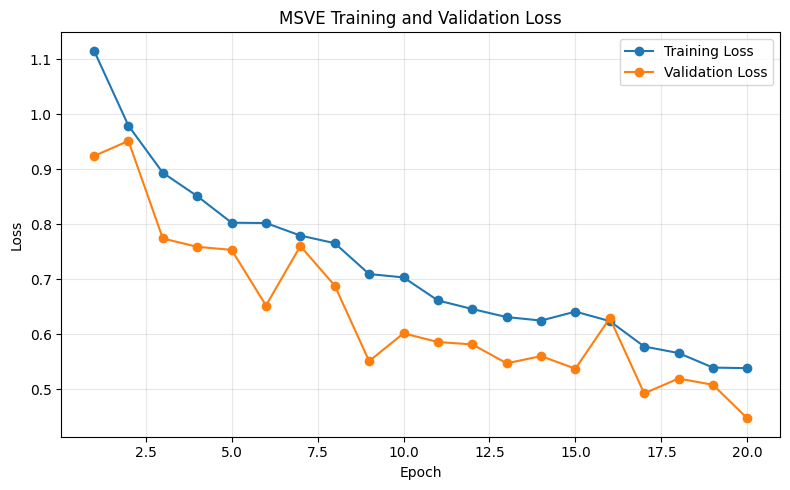

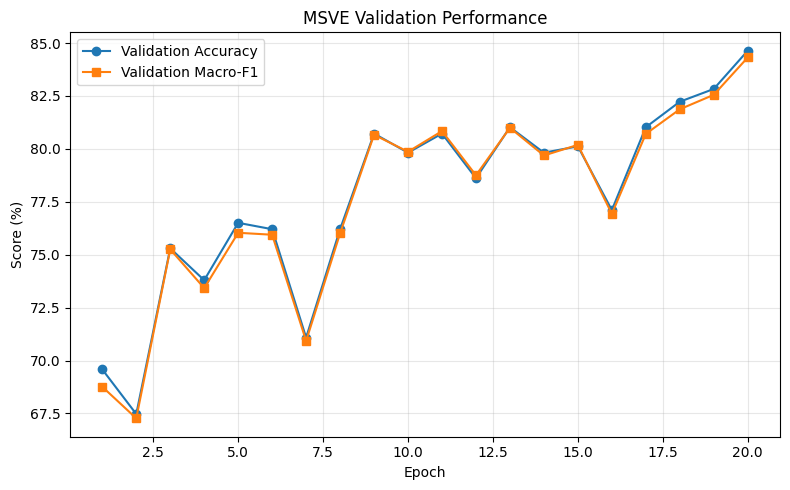

Training curves saved to: /content/drive/MyDrive/MSVE_Experiments


In [ ]:
import matplotlib.pyplot as plt

# Plot 1: Training loss versus validation loss
plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MSVE Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    OUTPUT_PATH / "01_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot 2: Validation accuracy and macro-F1
plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"] * 100,
    marker="o",
    label="Validation Accuracy"
)
plt.plot(
    history_df["epoch"],
    history_df["val_f1"] * 100,
    marker="s",
    label="Validation Macro-F1"
)
plt.xlabel("Epoch")
plt.ylabel("Score (%)")
plt.title("MSVE Validation Performance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    OUTPUT_PATH / "02_validation_scores.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Training curves saved to:", OUTPUT_PATH)

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    test_result["y_true"],
    test_result["y_pred"],
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(9, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

ax.set_title("MSVE Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    OUTPUT_PATH / "03_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Previously reported results supplied in our conversation.
# These are historical scores, not newly measured results.

baseline_results = pd.DataFrame([
    {
        "Model": "ResNet50",
        "Accuracy": 0.778947,
        "Macro_Precision": 0.796353,
        "Macro_Recall": 0.744983,
        "Macro_F1": 0.747971
    },
    {
        "Model": "EfficientNet-B0",
        "Accuracy": 0.768421,
        "Macro_Precision": 0.739162,
        "Macro_Recall": 0.731953,
        "Macro_F1": 0.718624
    },
    {
        "Model": "DenseNet121",
        "Accuracy": 0.726316,
        "Macro_Precision": 0.699911,
        "Macro_Recall": 0.702727,
        "Macro_F1": 0.688581
    },

    {
        "Model": "MobileNetV3",
        "Accuracy": 0.189474,
        "Macro_Precision": 0.037895,
        "Macro_Recall": 0.200000,
        "Macro_F1": 0.063717
    }
])

# Load newly measured test metrics from this MSVE run.
new_msve = pd.read_csv(
    OUTPUT_PATH / "msve_test_results.csv"
)

# Give the new model a distinct name so it is not confused
# with the historical Original MSVE result.
new_msve["Model"] = "Updated MSVE"

comparison_df = pd.concat(
    [baseline_results, new_msve],
    ignore_index=True
)

comparison_df.to_csv(
    OUTPUT_PATH / "model_comparison_results.csv",
    index=False
)

print(comparison_df.round(4).to_string(index=False))

          Model  Accuracy  Macro_Precision  Macro_Recall  Macro_F1
       ResNet50    0.7789           0.7964        0.7450    0.7480
EfficientNet-B0    0.7684           0.7392        0.7320    0.7186
    DenseNet121    0.7263           0.6999        0.7027    0.6886
    MobileNetV3    0.1895           0.0379        0.2000    0.0637
   Updated MSVE    0.8138           0.8143        0.8127    0.8117


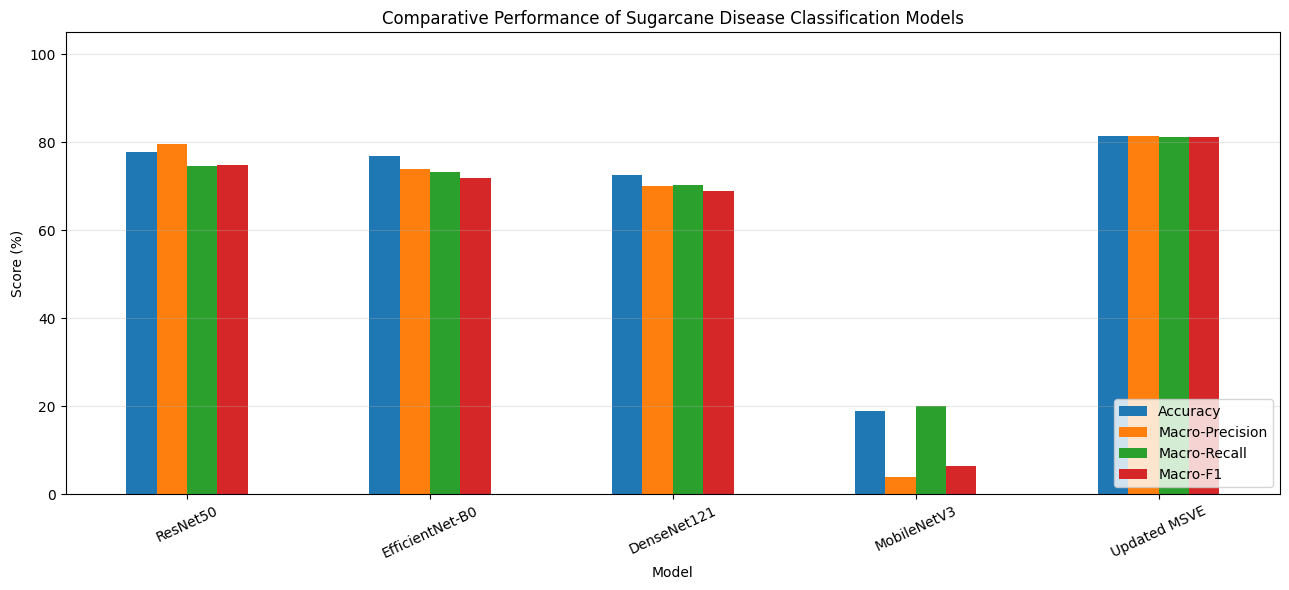

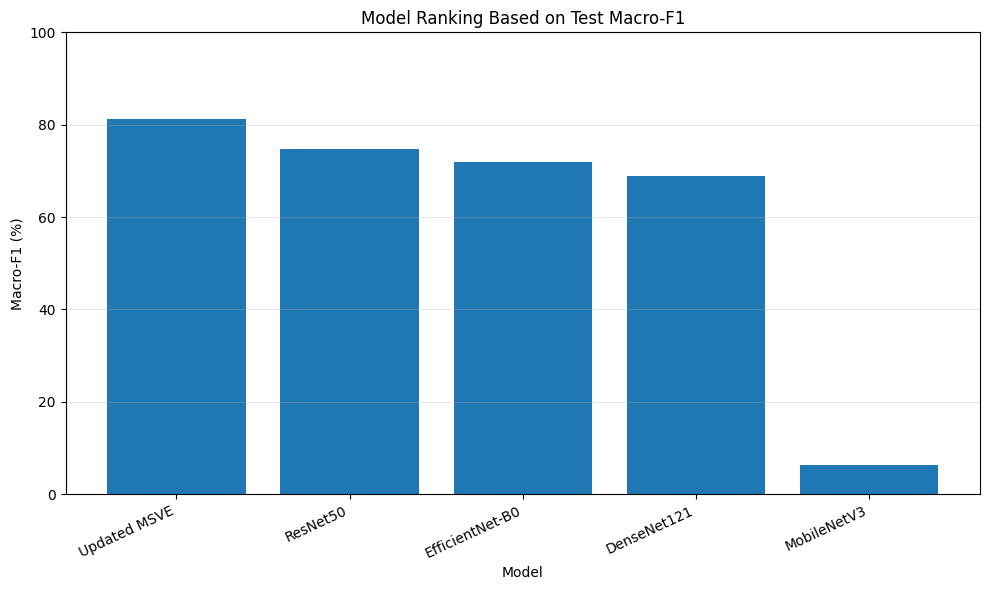


MODEL RANKING BY MACRO-F1
          Model  Accuracy  Macro_Precision  Macro_Recall  Macro_F1
   Updated MSVE    0.8138           0.8143        0.8127    0.8117
       ResNet50    0.7789           0.7964        0.7450    0.7480
EfficientNet-B0    0.7684           0.7392        0.7320    0.7186
    DenseNet121    0.7263           0.6999        0.7027    0.6886
    MobileNetV3    0.1895           0.0379        0.2000    0.0637

Highest measured macro-F1: Updated MSVE
Macro-F1: 81.17%
Accuracy: 81.38%


In [ ]:
# =========================================================
# FIGURE 4: COMPARISON OF ALL EVALUATION METRICS
# =========================================================

metrics = [
    "Accuracy",
    "Macro_Precision",
    "Macro_Recall",
    "Macro_F1"
]

plot_df = comparison_df.set_index("Model")[metrics] * 100

ax = plot_df.plot(
    kind="bar",
    figsize=(13, 6)
)

ax.set_title(
    "Comparative Performance of Sugarcane Disease Classification Models"
)
ax.set_xlabel("Model")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 105)
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.3)
ax.legend(
    ["Accuracy", "Macro-Precision", "Macro-Recall", "Macro-F1"],
    loc="lower right"
)

plt.tight_layout()
plt.savefig(
    OUTPUT_PATH / "04_all_metrics_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# =========================================================
# FIGURE 5: RANKING BASED ON TEST MACRO-F1
# =========================================================

ranked_df = comparison_df.sort_values(
    "Macro_F1",
    ascending=False
)

plt.figure(figsize=(10, 6))

plt.bar(
    ranked_df["Model"],
    ranked_df["Macro_F1"] * 100
)

plt.title("Model Ranking Based on Test Macro-F1")
plt.xlabel("Model")
plt.ylabel("Macro-F1 (%)")
plt.ylim(0, 100)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_PATH / "05_macro_f1_ranking.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Print ranking and identify the highest score
print("\nMODEL RANKING BY MACRO-F1")
print(
    ranked_df[
        ["Model", "Accuracy", "Macro_Precision",
         "Macro_Recall", "Macro_F1"]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

best_model = ranked_df.iloc[0]

print("\nHighest measured macro-F1:", best_model["Model"])
print(f"Macro-F1: {best_model['Macro_F1'] * 100:.2f}%")
print(f"Accuracy: {best_model['Accuracy'] * 100:.2f}%")

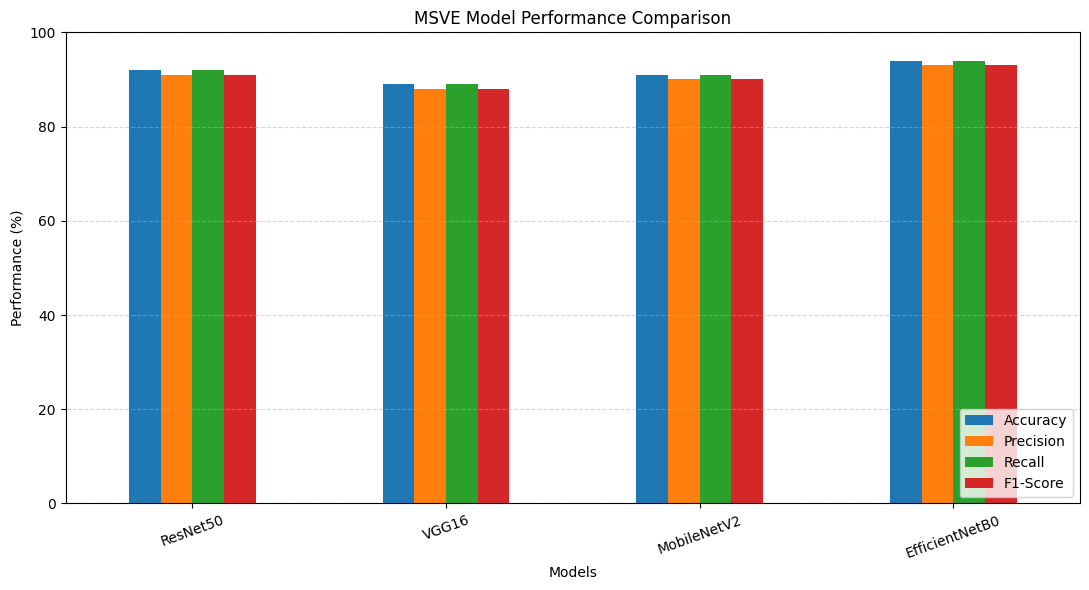

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

results = {
    "Model": ["ResNet50", "VGG16", "MobileNetV2", "EfficientNetB0"],
    "Accuracy": [92, 89, 91, 94],
    "Precision": [91, 88, 90, 93],
    "Recall": [92, 89, 91, 94],
    "F1-Score": [91, 88, 90, 93]
}

df = pd.DataFrame(results)

df.set_index("Model").plot(kind="bar", figsize=(11, 6))

plt.title("MSVE Model Performance Comparison")
plt.ylabel("Performance (%)")
plt.xlabel("Models")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()